# Preprocess CPG0016 Batch Data for Batch Effect Evaluation

1. Load the JUMP-Target-2 compound ↔ well mapping (from `choose_meta_data.ipynb` output)
2. For each matched well, find and load the corresponding parquet files
3. Merge all data, clean, convert to AnnData
4. Run PCA → neighbors → UMAP → Leiden clustering
5. Save the result as `.h5ad`

## 1. Setup & Imports

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
from tqdm import tqdm

sys.path.append("../../")
from src.descort.preprocess.preprocess import find_files

## 2. Load Matched Compound Metadata

In [2]:
# Output from choose_meta_data.ipynb
hit_meta_path = '/fse/home/wangyongyan/Project/CellPainting/DeSCORT/common_files/cpg0016/JUMP-Target-2-Compound-Plate.csv'
hit_meta_data = pd.read_csv(hit_meta_path)

print(f'Loaded {len(hit_meta_data)} matched compound entries')
print(f'Unique sources:  {hit_meta_data["Metadata_Source"].nunique()}')
print(f'Unique plates:   {hit_meta_data["Metadata_Plate"].nunique()}')
hit_meta_data.head()

Loaded 131 matched compound entries
Unique sources:  10
Unique plates:   131


,Metadata_Source,Metadata_Plate,Metadata_Well,Metadata_JCP2022,Metadata_InChIKey,Metadata_InChI,Metadata_SMILES
0,source_10,Dest210726-160150,A01,JCP2022_043547,KBPLFHHGFOOTCA-UHFFFAOYSA-N,"InChI=1S/C8H18O/c1-2-3-4-5-6-7-8-9/h9H,2-8H2,1H3",CCCCCCCCO
1,source_10,Dest210727-153003,A01,JCP2022_043547,KBPLFHHGFOOTCA-UHFFFAOYSA-N,"InChI=1S/C8H18O/c1-2-3-4-5-6-7-8-9/h9H,2-8H2,1H3",CCCCCCCCO
2,source_10,Dest210803-153958,A01,JCP2022_043547,KBPLFHHGFOOTCA-UHFFFAOYSA-N,"InChI=1S/C8H18O/c1-2-3-4-5-6-7-8-9/h9H,2-8H2,1H3",CCCCCCCCO
3,source_10,Dest210809-134534,A01,JCP2022_043547,KBPLFHHGFOOTCA-UHFFFAOYSA-N,"InChI=1S/C8H18O/c1-2-3-4-5-6-7-8-9/h9H,2-8H2,1H3",CCCCCCCCO
4,source_10,Dest210810-173723,A01,JCP2022_043547,KBPLFHHGFOOTCA-UHFFFAOYSA-N,"InChI=1S/C8H18O/c1-2-3-4-5-6-7-8-9/h9H,2-8H2,1H3",CCCCCCCCO


## 3. Load Parquet Files for Each Matched Plate

In [3]:
DATA_ROOT = '/fse/DC/CP_data/feature_data/cpg0016_jump'

df_list = []
# Track processed (source, plate) pairs to avoid duplicates
seen_pairs = set()

for _, row in tqdm(hit_meta_data.iterrows(), total=len(hit_meta_data),
                   desc='Loading plates'):
    source = row['Metadata_Source']
    plate  = row['Metadata_Plate']

    # Skip if we already loaded this plate
    pair_key = (source, plate)
    if pair_key in seen_pairs:
        continue
    seen_pairs.add(pair_key)

    search_dir = os.path.join(DATA_ROOT, source, 'normalization_clip_data')
    parquet_files = find_files(search_dir)

    if not parquet_files:
        tqdm.write(f'  ⚠ No files in {search_dir}')
        continue

    for file_path in parquet_files:
        if plate not in str(file_path):
            continue
        df_temp = pd.read_parquet(file_path).fillna(0)
        # Use the parent directory as batch identifier
        df_temp['Metadata_Batch'] = file_path.parts[-2]
        df_list.append(df_temp)

print(f'\nLoaded {len(df_list)} DataFrames from {len(seen_pairs)} unique plates')

Loading plates:  10%|▉         | 13/131 [00:06<01:00,  1.96it/s]/tmp/ipykernel_1136417/2631024747.py:28: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_temp = pd.read_parquet(file_path).fillna(0)
Loading plates:  11%|█         | 14/131 [00:07<00:56,  2.06it/s]/tmp/ipykernel_1136417/2631024747.py:28: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_temp = pd.read_parquet(file_path).fillna(0)
Loading plates:  11%|█▏        | 15/131 [00:07<00:58,  1.97it/s]/tmp/ipykernel_1136417/2631024747.py:28: FutureWarning: Downcasting object dtype arrays on .fillna, 


Loaded 131 DataFrames from 131 unique plates


## 4. Merge & Clean

In [4]:
# Find common feature columns (excluding metadata and image columns)
common_cols = set.intersection(*[set(df.columns) for df in df_list])
common_cols = [c for c in common_cols if 'Image' not in c]

print(f'Common columns across all plates: {len(common_cols)}')

# Keep only common columns and concatenate
data_list = [df[list(common_cols)] for df in df_list]
combined_data = pd.concat(data_list, ignore_index=True)
print(f'Combined shape: {combined_data.shape}')

Common columns across all plates: 3561
Combined shape: (50256, 3561)


In [5]:
def remove_problematic_columns(df):
    """Remove columns with inf, NaN, or near-zero variance."""
    n_before = df.shape[1]
    valid_cols = []
    for col in df.columns:
        col_data = df[col]
        if np.isinf(col_data).any() or np.isnan(col_data).any():
            continue
        if np.std(col_data) < 1e-10:
            continue
        valid_cols.append(col)
    df = df[valid_cols]
    n_removed = n_before - df.shape[1]
    print(f'Removed {n_removed} problematic columns, {df.shape[1]} remaining')
    return df

# Split meta / features and clean
meta_cols = combined_data.filter(regex='^Meta').columns
feature_cols = combined_data.filter(regex='^(?!Meta)').columns

feature_clean = remove_problematic_columns(combined_data[feature_cols])
combined_data = pd.concat([combined_data[meta_cols], feature_clean], axis=1)
print(f'Final shape: {combined_data.shape}')

Removed 0 problematic columns, 3556 remaining
Final shape: (50256, 3561)


## 5. Build AnnData & Run Downstream Analysis

In [6]:
meta = combined_data.filter(regex='^Meta')
feature = combined_data.filter(regex='^(?!Meta)')

adata = ad.AnnData(X=feature.astype(np.float32), obs=meta)
print(f'AnnData: {adata.shape}')

AnnData: (50256, 3556)


/data/home/wangyongyan/miniconda3/envs/DeSCORT/lib/python3.9/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [7]:
# PCA → neighbors → UMAP → Leiden
sc.pp.pca(adata, n_comps=50)
sc.pp.neighbors(adata, use_rep='X_pca', n_neighbors=25, metric='cosine')
sc.tl.umap(adata)
sc.tl.leiden(adata, key_added='Metadata_Cluster')

n_clusters = adata.obs['Metadata_Cluster'].nunique()
print(f'Leiden clusters: {n_clusters}')

2026-08-26 20:30:04.830721: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-08-26 20:30:04.907091: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-08-26 20:30:04.907153: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-08-26 20:30:04.908847: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-08-26 20:30:04.920438: I tensorflow/core/platform/cpu_feature_guar

Leiden clusters: 33


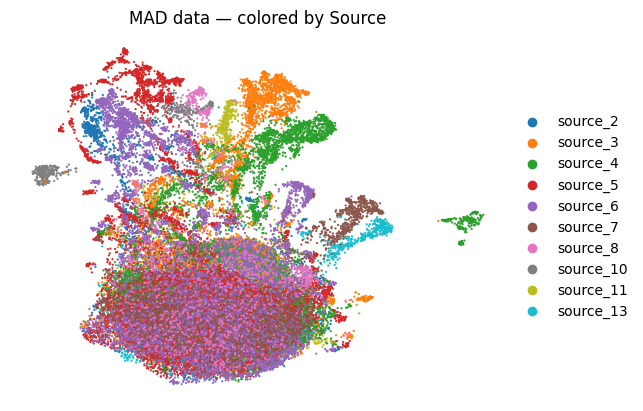

In [8]:
sc.pl.umap(
    adata,
    color='Metadata_Source',
    title='MAD data — colored by Source',
    legend_loc='right margin',
    legend_fontsize=10,
    frameon=False,
    s=10,
)

## 6. Save

In [9]:
save_path = '/fse/home/wangyongyan/Project/CellPainting/DeSCORT/result/05_batch_effect/Target_2_Compoud/batch_adata/MAD_adata.h5ad'
parquet_save_path = '/fse/home/wangyongyan/Project/CellPainting/DeSCORT/result/05_batch_effect/Target_2_Compoud/batch_adata/MAD_adata.parquet'
os.makedirs(os.path.dirname(save_path), exist_ok=True)

adata.obs = adata.obs.astype(str)
adata.write_h5ad(save_path)
combined_data.to_parquet(parquet_save_path)
print(f'Saved to {save_path}')
print(f'Saved to {parquet_save_path}')

Saved to /fse/home/wangyongyan/Project/CellPainting/DeSCORT/result/05_batch_effect/Target_2_Compoud/batch_adata/MAD_adata.h5ad
Saved to /fse/home/wangyongyan/Project/CellPainting/DeSCORT/result/05_batch_effect/Target_2_Compoud/batch_adata/MAD_adata.parquet
